[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L5/BA_L5_gmv_weights/BA_L5_gmv_weights.ipynb)

# BA_L5_gmv_weights: What the minimum-variance portfolio holds

*Quantlet of Lecture 5, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Monthly averages of the weekly global minimum variance weights (long only, capped at 30%, covariance of the last 90 days shrunk 10% towards its diagonal) of 10 stablecoins, June 2020 - May 2026, EODHD reference-adjusted returns.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

## What the minimum-variance portfolio holds

Global minimum variance (GMV) portfolio of the ten stablecoins, rebalanced every 7 days from 30 June 2020 with information up to day $t-1$:
$$ \min_w\; w'\hat\Sigma w \quad \text{subject to} \quad \sum_i w_i = 1,\; 0 \leq w_i \leq 0.3, \qquad \hat\Sigma = 0.9\,S + 0.1\,\mathrm{diag}(S), $$
with $S$ the sample covariance matrix of the daily simple reference-adjusted returns of the last 90 days (10% shrinkage towards the diagonal). Between rebalancings the weights drift with prices.

**Reference adjustment.** Let $P_{i,t}$ be the dollar price of token $i$ and $B_{i,t}$ the dollar value of its reference asset ($B = 1$ for dollar tokens, EUR/USD for STASIS Euro (EURS), XAU/USD for Pax Gold (PAXG)). The reference-adjusted deviation, in basis points (bp, 0.01%), is
$$ d_{i,t} = 10^4\left(\frac{P_{i,t}}{B_{i,t}} - 1\right). $$
Prices are put on a calendar of all days and filled from the past for at most 7 days; a daily move beyond 1,000 bp that reverses by at least 90% the next day is treated as a recording error and removed.

**How to read the chart.** Stacked monthly averages of the weights held each day, June 2020 – May 2026 (the paper's sample period); each band is one coin, the total is 100%.

In [4]:
# Data: 10 stablecoins, their reference assets and four market variables, 1 January 2020 - 23 October 2026
import matplotlib
plt.rcParams['font.size'] = 10
END, END_PAPER = '2026-10-23', '2026-05-31'          # last day of the lecture sample; last day of the paper's sample
COINS = ['USDT', 'USDC', 'DAI', 'TUSD', 'USDP', 'GUSD', 'BUSD', 'SUSD', 'PAXG', 'EURS']
cal = pd.date_range('2020-01-01', END)


def weekdays(x):
    """EUR/USD and gold: Monday-Friday closes, repeated closes removed (the weekend bars come from a thin session)."""
    x = x[x.index.dayofweek < 5]
    return x[x.diff() != 0]


def finish_fig(fig, name, bottom, ncol=3):
    """Legend below the plot, then save and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)


ref = {'EURS': weekdays(daily('EURUSD.FOREX', END)), 'PAXG': weekdays(daily('XAUUSD.FOREX', END))}
P = pd.DataFrame({c: daily(f'{c}-USD.CC', END) for c in COINS}).reindex(cal).ffill(limit=7)    # past-only fill, at most 7 days
lr = 1e4 * np.log(P).diff()
bad = (lr.abs() > 1000) & (-lr.shift(-1) / lr >= 0.9)      # bad print: a move beyond 1000 bp, reversed by >= 90% the next day
P_raw = P.copy()                                           # prices as recorded
P = P.mask(bad).ffill(limit=7)                             # retrospective cleaning
Bm = pd.DataFrame({c: (ref[c].reindex(cal).ffill() if c in ref else pd.Series(1.0, index=cal)) for c in COINS})
D = 1e4 * (P / Bm - 1)                                     # reference-adjusted deviation d (bp)
D_raw = 1e4 * (P_raw / Bm - 1)                             # same, prices as recorded
R = 1e4 * np.log(P / Bm).diff()                            # reference-adjusted log return (bp)
mac = pd.DataFrame({'DXY': daily('DXY.INDX', END), 'VIX': daily('VIX.INDX', END), 'SPX': daily('GSPC.INDX', END),
                    'US1Y': daily('US1Y.GBOND', END)}).reindex(cal).ffill()
M = pd.DataFrame({'DXY': np.log(mac['DXY']).diff(), 'VIX': np.log(mac['VIX']).diff(), 'SPX': np.log(mac['SPX']).diff(),
                  'US1Y': mac['US1Y'].diff()}).shift(1)     # market changes, lagged one day
print(f'calendar {cal[0].date()} to {cal[-1].date()} ({len(cal)} days); bad prints removed: {int(bad.values.sum())}')

calendar 2020-01-01 to 2026-10-23 (2488 days); bad prints removed: 9


In [5]:
# Portfolio rules, rebalanced every 7 days with information up to t-1; weights capped at 30%
from scipy.optimize import minimize
RS = np.expm1(R / 1e4)                                                 # simple reference-adjusted return of day t
RS_rt = np.expm1((np.log(P_raw / Bm) - np.log(P / Bm).shift(1)))       # day-s return as seen at the end of day s


def gmv(hist, avail):
    """Global minimum variance, long only, cap 30%, covariance shrunk 10% towards its diagonal."""
    S = hist[avail].cov().values
    S = 0.9 * S + 0.1 * np.diag(np.diag(S))
    Sn = S / np.median(np.diag(S))                                     # rescale: variances differ by up to 1e6
    x0 = 1 / np.diag(Sn); x0 = np.minimum(x0 / x0.sum(), 0.3); x0 /= x0.sum()
    r_ = minimize(lambda w: w @ Sn @ w, x0, jac=lambda w: 2 * Sn @ w, bounds=[(0, 0.3)] * len(avail),
                  constraints=({'type': 'eq', 'fun': lambda w: w.sum() - 1},), method='SLSQP',
                  options={'ftol': 1e-12, 'maxiter': 500})
    w = np.clip(r_.x, 0, None)
    return pd.Series(w / w.sum(), index=avail)


def targets(t_, rules):
    """Target weights at the close of day t-1, from information up to t-1 (the last day as recorded)."""
    hist = RS.loc[:t_ - pd.Timedelta(days=1)].iloc[-90:].copy()
    hist.iloc[-1] = RS_rt.loc[t_ - pd.Timedelta(days=1)]
    avail = [c for c in COINS if hist[c].notna().all() and not np.isnan(P_raw[c].loc[t_ - pd.Timedelta(days=1)])]
    new = {'equal weight': pd.Series(1 / len(avail), index=avail), 'global minimum variance': gmv(hist, avail)}
    if 'linear lambda' in rules:                                       # fill the coins with the lowest penalty first
        lam_ = LAM.loc[:t_ - pd.Timedelta(days=1)].iloc[-1].reindex(avail).fillna(np.inf)
        wl = pd.Series(0.0, index=avail); left = 1.0
        for c in lam_.sort_values().index:
            wl[c] = min(0.3, left); left -= wl[c]
            if left <= 1e-12:
                break
        new['linear lambda'] = wl
    return {k: new[k].reindex(COINS).fillna(0.0) for k in rules}


def run(end, rules):
    """Holdings simulation from 30 June 2020: reset to the targets every 7 days, weights drift with prices in between."""
    days_ = R.loc['2020-06-30':end].index
    reb = set(days_[::7])
    held = {k: None for k in rules}
    W = {k: pd.DataFrame(0.0, index=days_, columns=COINS) for k in rules}
    rp = {k: pd.Series(0.0, index=days_) for k in rules}
    turn = {k: [] for k in rules}
    for t_ in days_:
        if t_ in reb:
            tg = TG[t_]
            for k in rules:
                if held[k] is not None:
                    turn[k].append(0.5 * (tg[k] - held[k]).abs().sum())
                held[k] = tg[k].copy()
        r_t = RS.loc[t_].reindex(COINS).fillna(0.0)
        for k in rules:
            W[k].loc[t_] = held[k]
            g = held[k] * (1 + r_t)
            rp[k].loc[t_] = g.sum() - 1
            held[k] = g / g.sum()                                      # drift
    out = {}
    for k in rules:
        v = 1e4 * rp[k].values                                         # bp a day
        nav = np.cumprod(1 + rp[k].values)
        out[k] = {'return (% a year)': v.mean() * 365 / 100, 'volatility (% a year)': v.std() * np.sqrt(365) / 100,
                  'ES 5% (bp a day)': -v[v <= np.quantile(v, 0.05)].mean(),
                  'max drawdown (%)': 100 * (1 - nav / np.maximum.accumulate(nav)).max(),
                  'turnover per rebalance (%)': 100 * np.mean(turn[k])}
    return pd.DataFrame(out).T, W, pd.DataFrame(rp)

RULES = ['equal weight', 'global minimum variance']
TG = {t_: targets(t_, RULES) for t_ in R.loc['2020-06-30':END_PAPER].index[::7]}
PT, Wp, _ = run(END_PAPER, RULES)

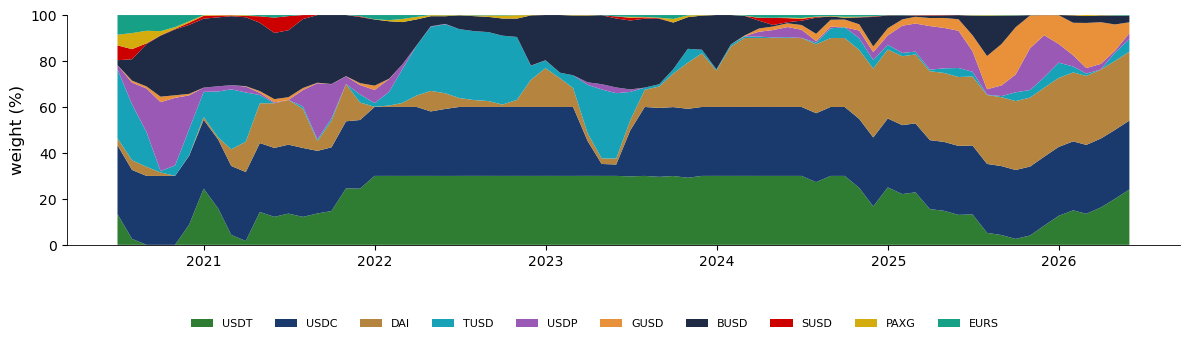

In [6]:
gw = Wp['global minimum variance'].resample('ME').mean() * 100
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.stackplot(gw.index, [gw[c] for c in COINS], labels=COINS, colors=[GREEN, BLUE, GOLD, TEAL, ETH, BTC, NAVY, RED, '#D4AC0D', '#16A085'])
ax.set_ylabel('weight (%)'); ax.set_ylim(0, 100)
finish_fig(fig, 'ba_l5_gmv_weights', 0.15, ncol=10)

In [7]:
(100 * Wp['global minimum variance'].mean()).sort_values(ascending=False).round(1).rename('average GMV weight, 30 Jun 2020 - 31 May 2026 (%)').to_frame()

,"average GMV weight, 30 Jun 2020 - 31 May 2026 (%)"
USDC,28.8
USDT,21.1
DAI,16.9
BUSD,14.9
TUSD,8.2
USDP,5.2
GUSD,3.1
EURS,0.8
SUSD,0.5
PAXG,0.5


The portfolio is mostly USDC, USDT, DAI and BUSD; sUSD, PAXG and EURS stay below 1% each. The 30% cap binds often: without it GMV would hold even more USDC and USDT, that is, more issuer concentration.